In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from ipynb.fs.full.model import build_nn_model, train_model, plot_loss_and_mae, evaluate_model 

from sklearn.model_selection import train_test_split
from numpy.lib.stride_tricks import sliding_window_view
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_squared_error
import tensorflow as tf
from sklearn.preprocessing import StandardScaler

from pandas import DataFrame
from pandas import concat

I0000 00:00:1794328846.712428 2319519 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794328846.745568 2319519 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1794328847.465221 2319519 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


<h3>Importing The Data

Text(0.5, 0.98, 'All Data')

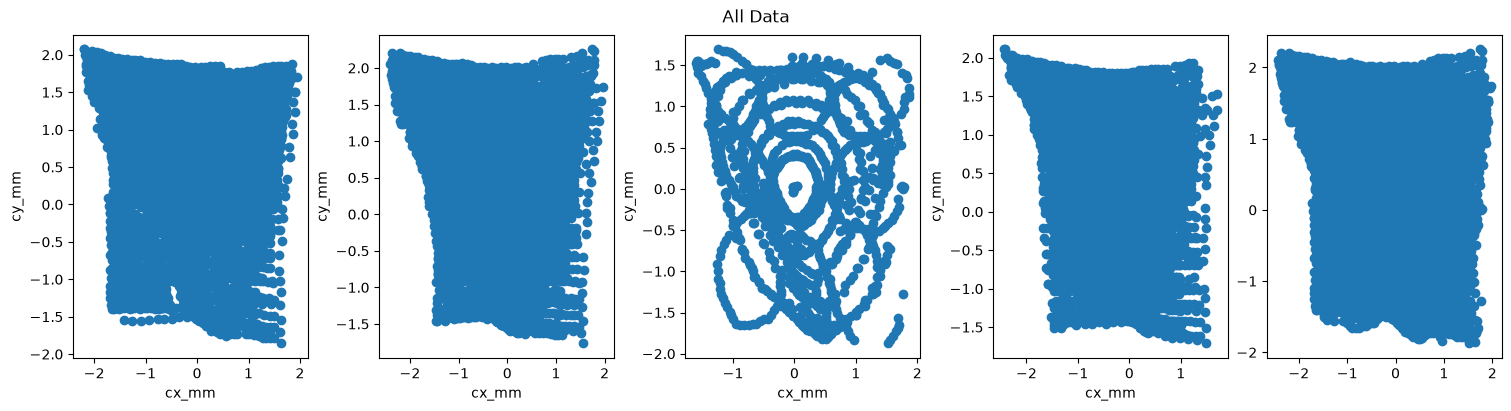

In [2]:
data_0 = pd.read_csv("processed_data/16Oct_data_corrected.csv", dtype="float32") #data was saved as float32, by default this was importing as float64
data_1 = pd.read_csv("processed_data/27Oct_data.csv", dtype="float32") #data was saved as float32, by default this was importing as float64
data_2 = pd.read_csv("processed_data/28Oct_data.csv", dtype="float32") #data was saved as float32, by default this was importing as float64
data_3 = pd.read_csv("processed_data/29Oct_data.csv", dtype="float32") #data was saved as float32, by default this was importing as float64
data_0 = data_0.dropna()
data_1 = data_1.dropna()
data_2 = data_2.dropna()
data_3 = data_3.dropna()
data_list = [data_0, data_1, data_2, data_3]

all_data = pd.concat(data_list, ignore_index=True)

fig, axs = plt.subplots(1, 5, figsize=(15,4), constrained_layout=True)
for i, data in enumerate(data_list):
    subplot = axs[i]
    subplot.scatter(data["cx_mm"], data["cy_mm"])
    subplot.set_xlabel("cx_mm")
    subplot.set_ylabel("cy_mm")
axs[4].scatter(all_data["cx_mm"], all_data["cy_mm"])
fig.suptitle("All Data")

<h3>MLP Inverse - with direction

In [3]:
all_data["cx_diff"] = all_data["cx_mm"].diff().round(1)
all_data["cy_diff"] = all_data["cy_mm"].diff().round(1)
all_data["cx_direction"] =  np.sign(all_data["cx_diff"])
all_data["cy_direction"] = np.sign(all_data["cy_diff"])

# dataset_test = data_concat.tail(442).reset_index()
# all_data = all_data[["cx_mm", "cy_mm","cx_direction","cy_direction", "s0", "s1", "s2"]].drop(data_concat.tail(442).index).drop(0) #reset indexes as multiple datapoints combined
# #"cx_diff","cy_diff",
all_data = all_data.dropna()
all_data.head(10)

,Unnamed: 0,point,time,x,y,x_rb,y_rb,s0,s1,s2,...,roi_x_max,roi_y_max,cx_rel,cy_rel,cx_mm,cy_mm,cx_diff,cy_diff,cx_direction,cy_direction
1,1.0,1.0,2.699900,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,...,434.0,400.0,0.0,0.0,0.000000,0.000000,0.0,0.0,0.0,0.0
2,2.0,0.0,23.035400,1.2,1.2,1.200032,1.2,6144.0,-8393.0,2249.0,...,220.0,212.0,-214.0,-188.0,1.945455,1.709091,1.9,1.7,1.0,1.0
3,3.0,1.0,25.126699,1.1,1.2,1.099897,1.2,6144.0,-7949.0,1805.0,...,234.0,216.0,-200.0,-184.0,1.818182,1.672727,-0.1,-0.0,-1.0,0.0
4,4.0,2.0,27.201900,1.0,1.2,0.999989,1.2,6144.0,-7506.0,1362.0,...,248.0,216.0,-186.0,-184.0,1.690909,1.672727,-0.1,0.0,-1.0,0.0
5,5.0,3.0,29.257000,0.9,1.2,0.900080,1.2,6144.0,-7063.0,919.0,...,266.0,220.0,-168.0,-180.0,1.527273,1.636364,-0.2,-0.0,-1.0,0.0
6,6.0,4.0,31.410299,0.8,1.2,0.799946,1.2,6144.0,-6619.0,475.0,...,286.0,222.0,-148.0,-178.0,1.345455,1.618182,-0.2,-0.0,-1.0,0.0
7,7.0,5.0,33.479698,0.7,1.2,0.700037,1.2,6144.0,-6176.0,32.0,...,306.0,224.0,-128.0,-176.0,1.163636,1.600000,-0.2,-0.0,-1.0,0.0
8,8.0,6.0,35.552200,0.6,1.2,0.599903,1.2,6144.0,-5732.0,-412.0,...,324.0,226.0,-110.0,-174.0,1.000000,1.581818,-0.2,-0.0,-1.0,0.0
9,9.0,7.0,37.626701,0.5,1.2,0.499994,1.2,6144.0,-5289.0,-855.0,...,340.0,226.0,-94.0,-174.0,0.854545,1.581818,-0.1,0.0,-1.0,0.0
10,10.0,8.0,39.701099,0.4,1.2,0.400086,1.2,6144.0,-4846.0,-1298.0,...,358.0,228.0,-76.0,-172.0,0.690909,1.563636,-0.2,-0.0,-1.0,0.0


In [4]:
scalerX = StandardScaler().fit(all_data[["cx_mm", "cy_mm","cx_direction","cy_direction"]])
scalerY = StandardScaler().fit(all_data[["s0", "s1", "s2"]])

X_scaled_all = scalerX.transform(all_data[["cx_mm", "cy_mm","cx_direction","cy_direction"]])
y_scaled_all = scalerY.transform(all_data[["s0", "s1", "s2"]])

In [5]:
def build_nn_model(input_dim, output_dim, architecture='standard'):
    """Build a neural network model with specified architecture"""
    
    if architecture == 'standard':
        model = tf.keras.Sequential([
            tf.keras.layers.Input(shape=(input_dim,)),
            tf.keras.layers.Dense(32, activation='relu'),#  kernel_regularizer='l1'),
            tf.keras.layers.Dense(output_dim)
        ])

    model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='mse',
    metrics=['mae'])

    model.summary()

    return model

def train_model(model, X_train, y_train, epochs=100, patience=30, verbose=0):
    # callbacks = [
    # tf.keras.callbacks.EarlyStopping(
    #     monitor='val_loss',
    #     patience=patience,
    #     restore_best_weights=True
    # )]

    history = model.fit(
    X_train,
    y_train,
    validation_split=0.2,
    verbose=verbose, 
    epochs=epochs,
    # callbacks=callbacks
    )
    # print(patience)
    return history

def plot_motors(y_test, y_pred, lims): 
    fig, axs = plt.subplots(1, 3)

    for i,motor in enumerate(["s0", "s1", "s2"]):
        subplot = axs[i]
        subplot.scatter(y_test[:,i], y_pred[:,i])
        subplot.set_xlabel('True Values')
        subplot.set_ylabel('Predictions')
        _ =subplot.plot(lims, lims, color="red")
        subplot.set_title(motor)
        subplot.plot()

In [6]:
scalerX = StandardScaler().fit(all_data[["cx_mm", "cy_mm", "cx_direction","cy_direction"]])
scalerY = StandardScaler().fit(all_data[["s0", "s1", "s2"]])
X_scaled = scalerX.transform(all_data[["cx_mm", "cy_mm", "cx_direction","cy_direction"]])
y_scaled = scalerY.transform(all_data[["s0", "s1", "s2"]])

Fold, 0:
  Train: index=0 to 3165 
  Test:  index=3166 to 6329


W0000 00:00:1794328851.428550 2319519 gpu_device.cc:2365] Cannot dlopen some GPU libraries. Please make sure the missing libraries mentioned above are installed properly if you would like to use GPU. Follow the guide at https://www.tensorflow.org/install/gpu for how to download and setup the required libraries for your platform.
Skipping registering GPU devices...


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 259 (1.01 KB)

 Trainable params: 259 (1.01 KB)

... (10 outputs left out)

 Total params: 259 (1.01 KB)

 Trainable params: 259 (1.01 KB)

 Non-trainable params: 0 (0.00 B)


Fold: 2 Results (scaled):
  Overall R2:  0.9588
  Weighted R2: 0.9587
MSE scores for each fold: [0.031879764050245285, 0.057054102420806885, 0.03914914280176163]


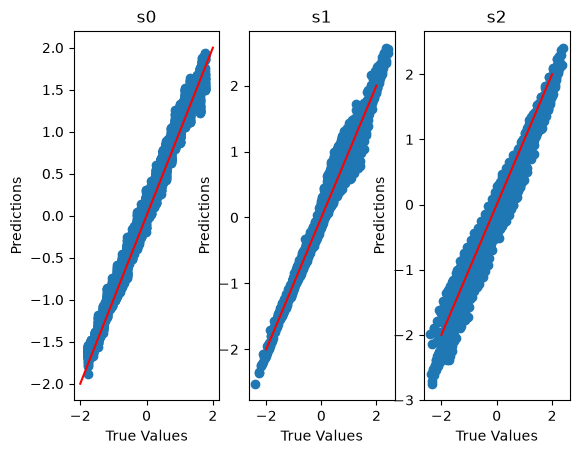

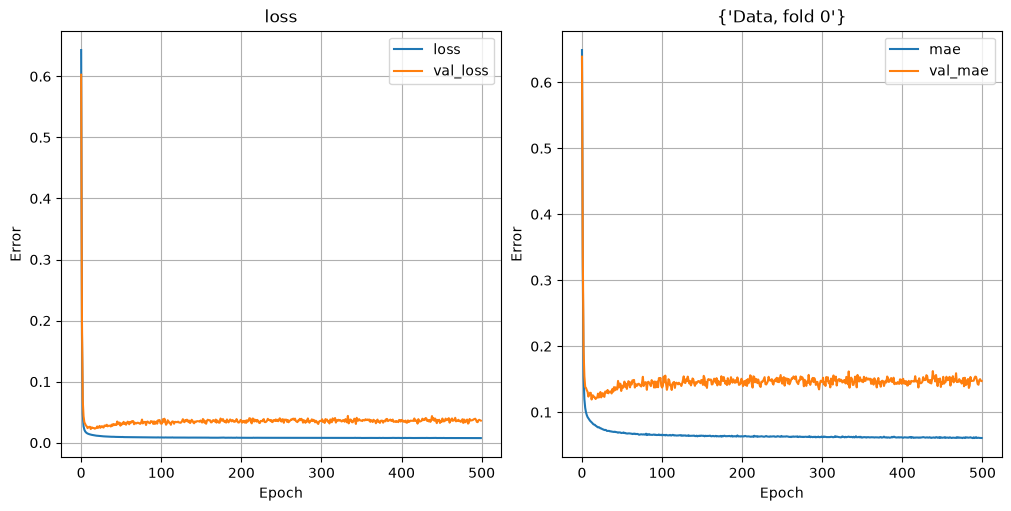

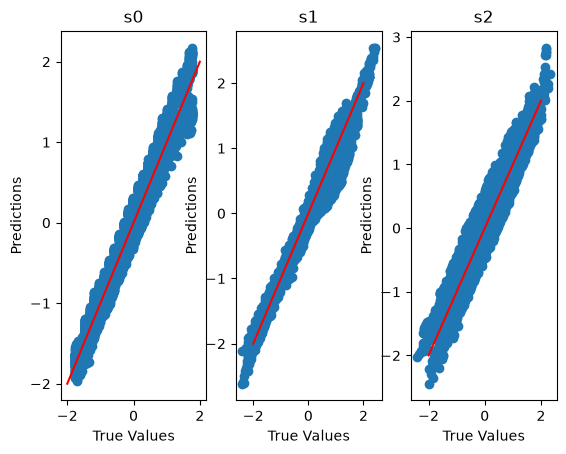

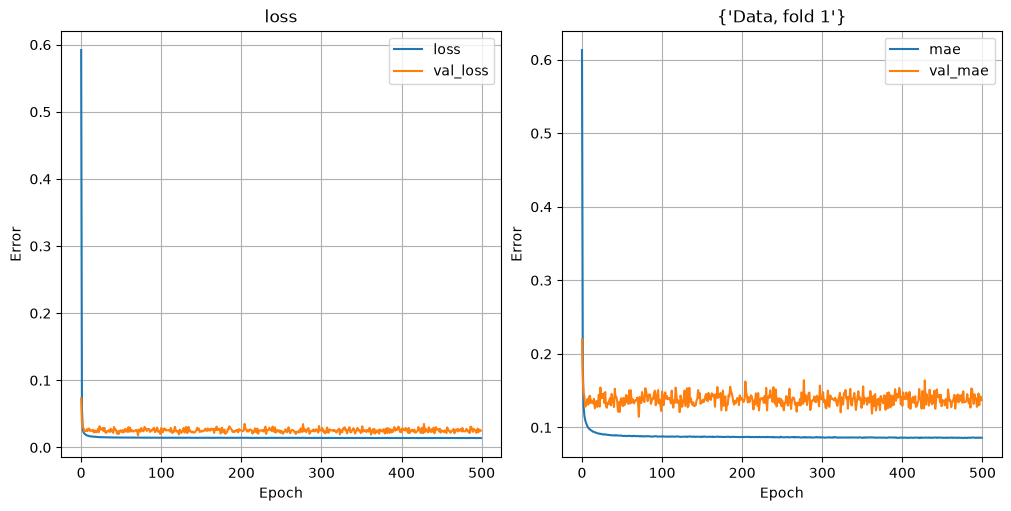

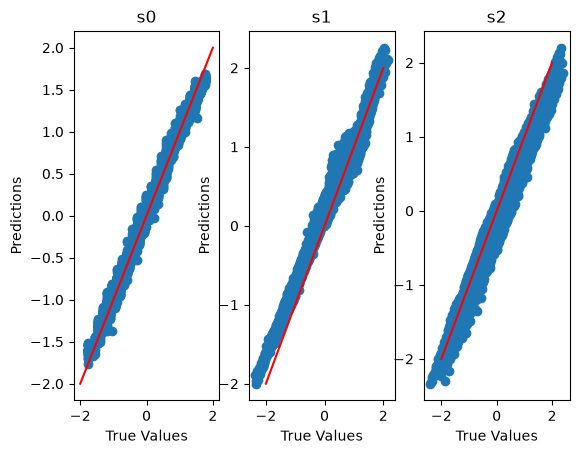

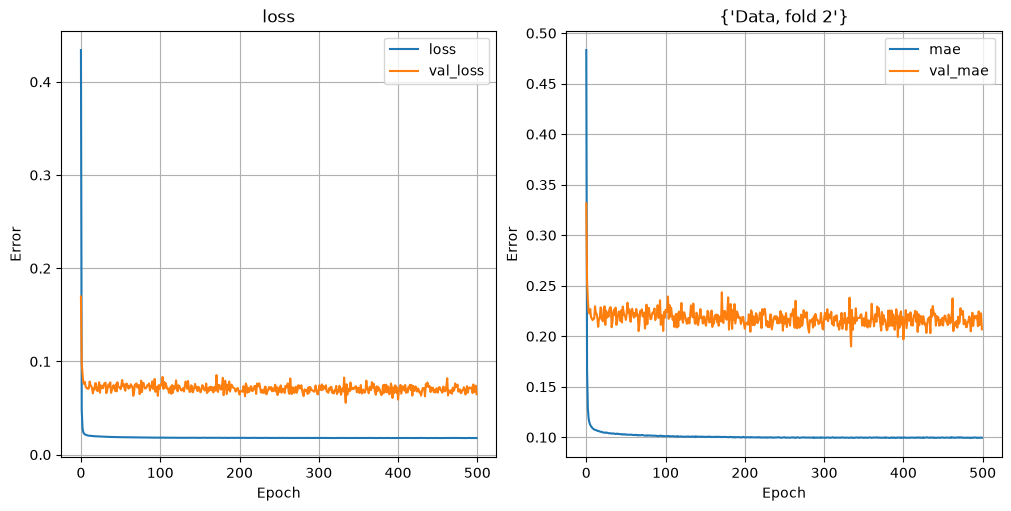

In [7]:
#Training with all data concatenated
# model = build_nn_model(2, 3) #usually not hardcoded - X_train_scaled.shape[1], y_train_scaled.shape[1]
# model.summary() #investigate
scores = []

X = X_scaled_all
y = y_scaled_all

tscv = TimeSeriesSplit(n_splits=3) #, test_size=712
for i, (train_index, test_index) in enumerate(tscv.split(X)):
    print(f"Fold, {i}:")
    print(f"  Train: index={train_index[0]} to {train_index[-1]} ")
    print(f"  Test:  index={test_index[0]} to {test_index[-1]}")
    
    X_train, X_test = X[train_index], X[test_index]
    y_train, y_test = y[train_index], y[test_index]

    model = build_nn_model(X_train.shape[1], y_train.shape[1])

    history = train_model(model, X_train, y_train, verbose=0, epochs=500, patience=1)
    y_pred = model.predict(X_test, verbose=0)

    evaluate_model(f"Fold: {i}", y_test, y_pred, is_scaled=True)
    plot_motors(y_test, y_pred, [-2,2])

    error = mean_squared_error(y_test, y_pred)
    scores.append(error)
    plot_loss_and_mae(history)
    plt.title({f"Data, fold {i}"})

print("MSE scores for each fold:", scores)

In [8]:
y_pred_inverse = scalerY.inverse_transform(y_pred)
y_test_inverse = scalerY.inverse_transform(y_test)
y_pred_inverse = DataFrame(y_pred_inverse)
# y_pred_inverse_all = y_pred_inverse
# y_pred_inverse_all[2]= -(y_pred_inverse_all[0] + y_pred_inverse_all[1])
y_pred_inverse


,0,1,2
0,-4412.142090,5197.228516,-783.588257
1,-4444.804199,5533.211914,-1075.835449
2,-4449.864746,5775.880371,-1313.752319
3,-4453.659180,5957.880859,-1492.189941
4,-4507.375000,6238.346680,-1719.598511
...,...,...,...
3159,5374.601562,-4821.175293,-537.685974
3160,5365.262695,-5227.832031,-121.832504
3161,5327.658691,-5656.896973,345.343414
3162,449.412384,1342.713623,-1789.810425


In [9]:
y_test_inverse

array([[-4352.    ,  5280.    ,  -928.    ],
       [-4352.    ,  5501.    , -1149.    ],
       [-4352.    ,  5723.    , -1371.    ],
       ...,
       [ 5120.    , -6994.    ,  1874.0001],
       [    0.    ,     0.    ,     0.    ],
       [    0.    ,     0.    ,     0.    ]],
      shape=(3164, 3), dtype=float32)

0


IndexError: only integers, slices (`:`), ellipsis (`...`), numpy.newaxis (`None`) and integer or boolean arrays are valid indices

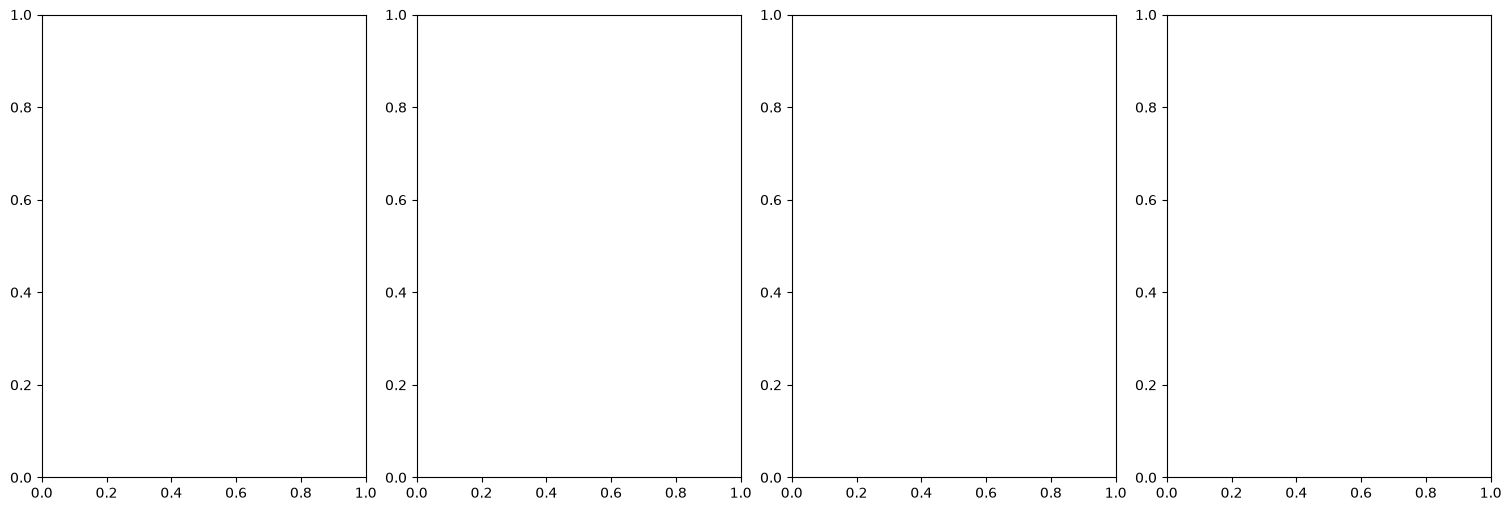

In [ ]:

y_test_all = y_test
fig, axs = plt.subplots(1,4, figsize=(15,5), constrained_layout=True)

for j, label in enumerate(['s0', 's1', 's2']):
    print(j)
    subplot = axs[j]
    axs[j].scatter(y_test_all[label], y_pred_inverse[i])
    lims = [-10000, 10000]
    subplot.set_xlabel('True Values')
    subplot.set_ylabel('Predictions')
    # subplot.set_xlim(lims)
    # subplot.set_ylim(lims)
    _ =subplot.plot(lims, lims, color="red")
    subplot.set_title(label)

subplot = axs[3]
subplot.scatter(y_test_inverse, y_pred_inverse)
subplot.set_xlabel('True Values')
subplot.set_ylabel('Predictions')
lims = [-11000, 10000]
# plt.xlim(lims)
# plt.ylim(lims)
_ = subplot.plot(lims, lims, color="red")
subplot.set_title("All")
print(len(y_test_all), len(y_pred))

fig.suptitle("All data Windowed Test Predictions not flattened")

<h2> Predicting for normal square - snake



In [ ]:
plt.scatter(mesh0045_27Oct["x"], mesh0045_27Oct["y"], c=mesh0045_27Oct["point"])
plt.colorbar()

In [ ]:
X_scaled_0020 = scalerX.transform(cxcy_window_0020)

In [ ]:
snake_predictions = model.predict(X_scaled_0020)

In [ ]:
snake_pred_inverse = scalerY.inverse_transform(snake_predictions)

In [ ]:
print(snake_pred_inverse)
np.savetxt("predictions/16Oct_MLP_Window_Pred_snake_mesh.csv", snake_pred_inverse, delimiter=',')